In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


url = "https://www.statlearning.com/s/Auto.csv"
Auto = pd.read_csv(url)
Auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [3]:
Auto['mpg01'] = [int(b) for b in Auto['mpg'] > Auto['mpg'].median()]
Auto['mpg01'].value_counts()

mpg01
0    206
1    191
Name: count, dtype: int64

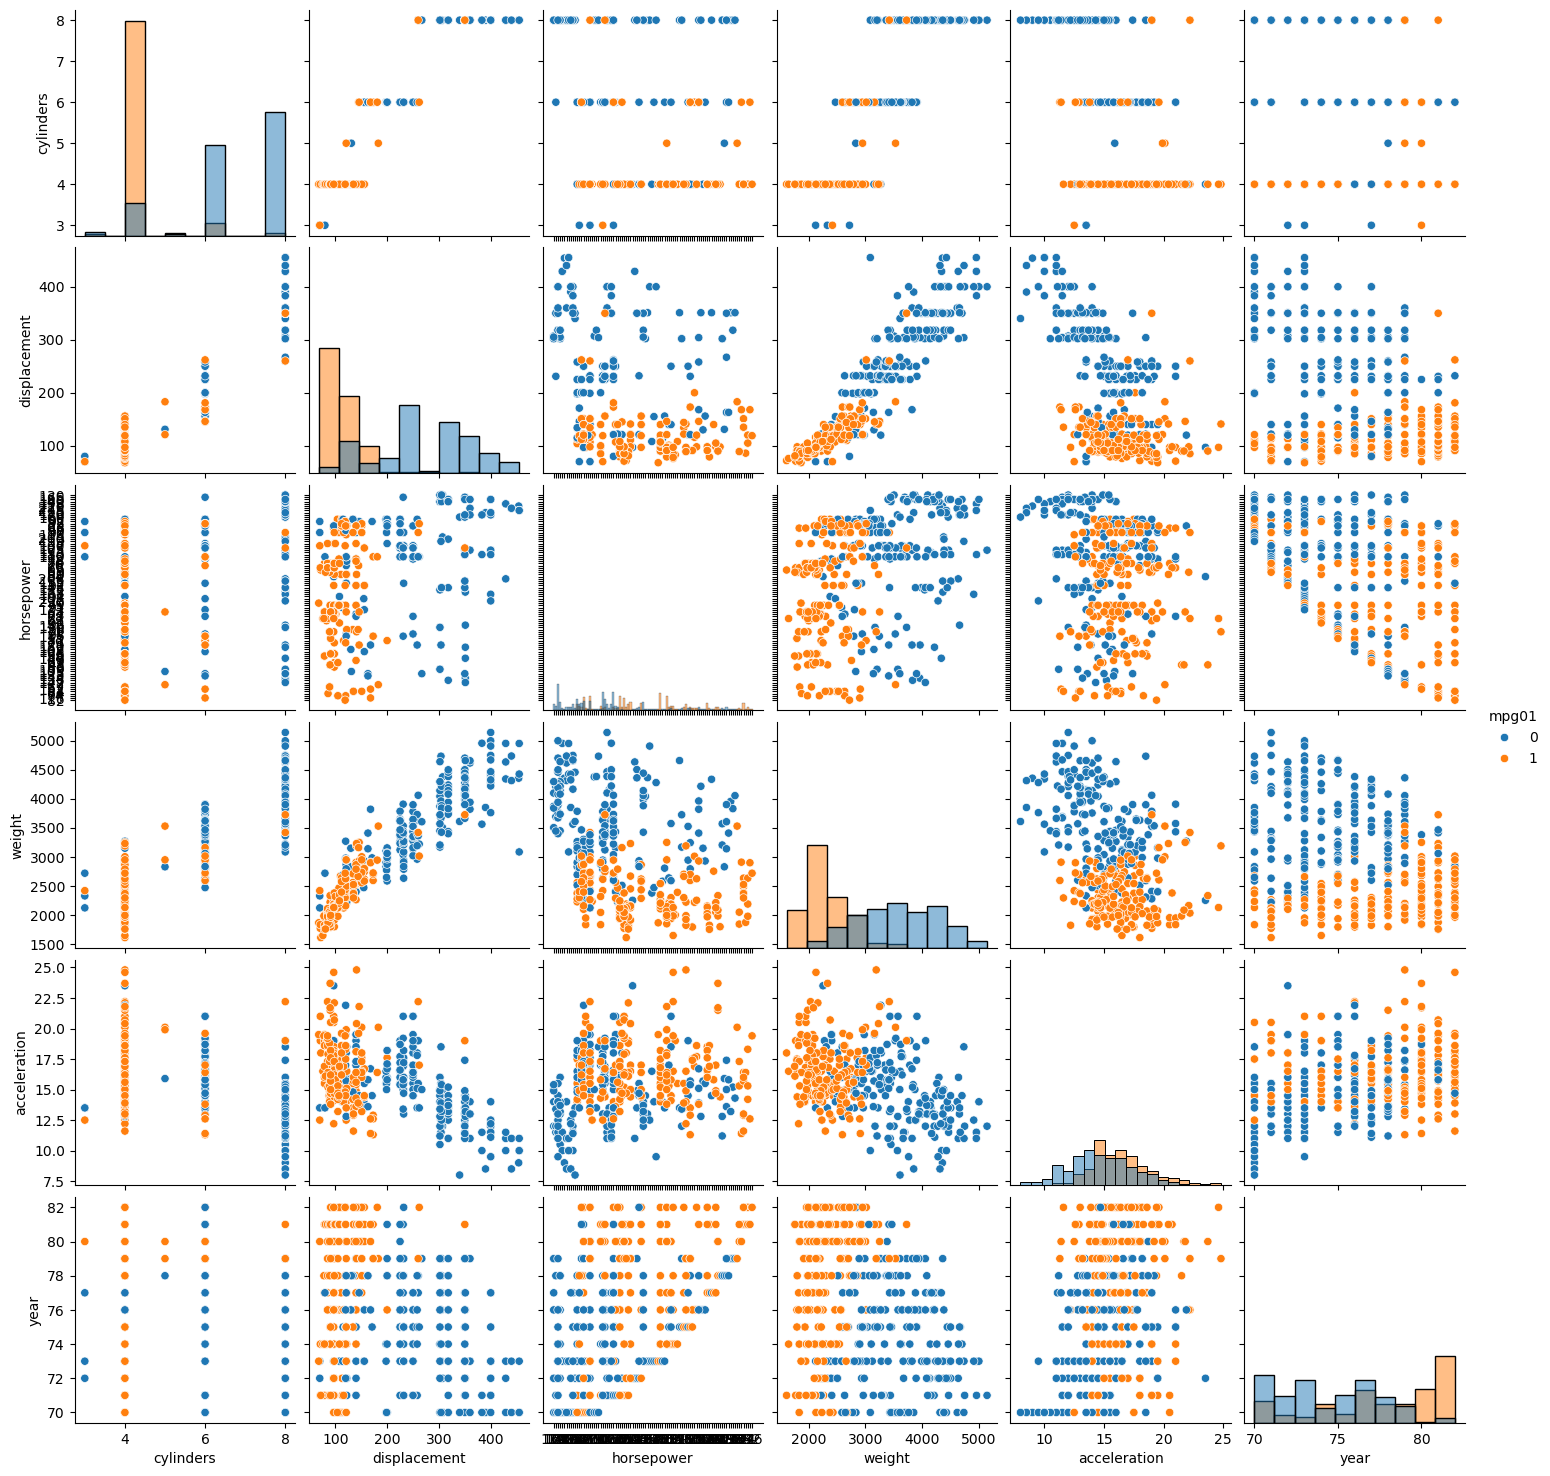

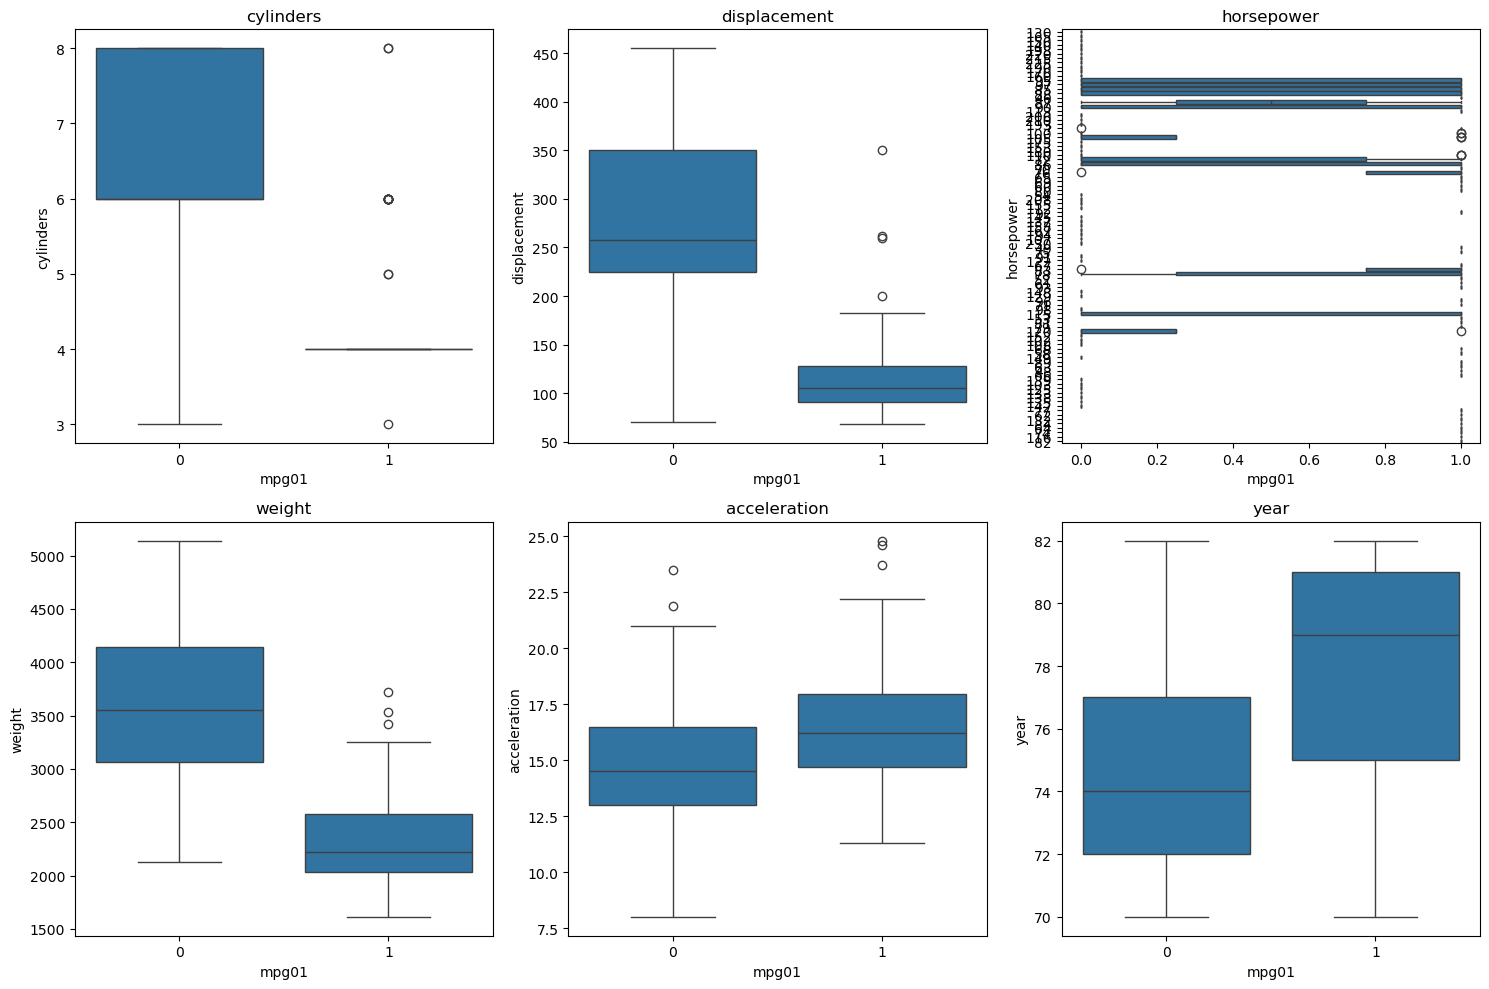

In [4]:
sns.pairplot(Auto, hue='mpg01', vars=['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year'], diag_kind='hist')
plt.show()
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
features = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year']
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(x='mpg01', y=feat, data=Auto, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

In [5]:
X = Auto[['cylinders', 'displacement', 'weight']].values
y = Auto['mpg01'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [6]:
lda = LDA()
lda.fit(X_train, y_train)
y_pred_lda = lda.predict(X_test)

lda_error = 1 - accuracy_score(y_test, y_pred_lda)
print(f"LDA test error: {lda_error:.4f}")

LDA test error: 0.1083


In [7]:
qda = QDA()
qda.fit(X_train, y_train)
y_pred_qda = qda.predict(X_test)
qda_error = 1 - accuracy_score(y_test, y_pred_qda)
print(f"QDA test error: {qda_error:.4f}")

QDA test error: 0.1083


In [8]:
log_reg = LogisticRegression(max_iter=1000)  # Increase max_iter to ensure convergence
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

lr_error = 1 - accuracy_score(y_test, y_pred_lr)
print(f"Logistic regression test error: {lr_error:.4f}")

Logistic regression test error: 0.1333


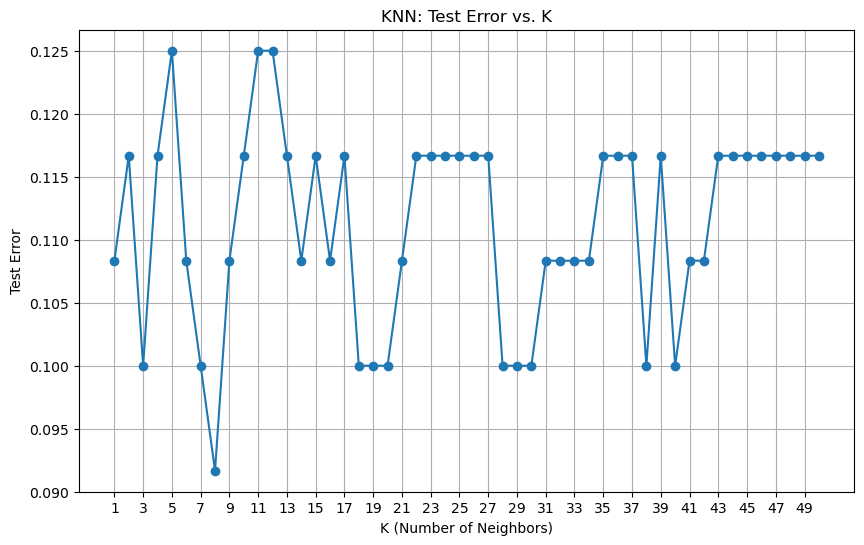

Best K: 8, corresponding test error: 0.0917


In [9]:
k_values = range(1, 51)
knn_errors = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred_knn = knn.predict(X_test)
    error = 1 - accuracy_score(y_test, y_pred_knn)
    knn_errors.append(error)

# Plot test error against K
plt.figure(figsize=(10, 6))
plt.plot(k_values, knn_errors, marker='o', linestyle='-')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Test Error')
plt.title('KNN: Test Error vs. K')
plt.xticks(range(1, 51, 2))
plt.grid(True)
plt.show()

# Find the best K value
best_k = k_values[np.argmin(knn_errors)]
best_error = min(knn_errors)
print(f"Best K: {best_k}, corresponding test error: {best_error:.4f}")